# Encontro 4 — Reprodutibilidade e o DisSModel

**Modelagem Dinâmica Espacial · PPGC&TAmb/UFMA**

Neste notebook você **não precisa escrever código**: rode as células na ordem (Shift+Enter), leia as saídas e responda às perguntas marcadas com ✏️. Em alguns lugares você vai trocar um número e rodar de novo.

Ao final, você deve saber responder:

1. O que significa dizer que um resultado é *reprodutível*?
2. Quais informações de uma execução precisam ser guardadas para outra pessoa repeti-la?
3. Por que dois arquivos com o mesmo conteúdo podem ter "impressões digitais" diferentes?
4. Como o DisSModel registra essas informações sem que você precise lembrar delas?

## 0. Preparação

Se estiver no Colab, descomente a primeira linha e rode. No laboratório o ambiente já está instalado.

In [1]:
# !pip install -q "dissmodel==0.6.6" "dissmodel-ca @ git+https://github.com/DisSModel/dissmodel-ca.git@v0.2.0"
import hashlib, json, sqlite3, glob, os
import geopandas as gpd
import warnings
import dissmodel, dissmodel_ca

# esconde um aviso do pyogrio que não afeta o resultado
warnings.filterwarnings("ignore", message=".*non conformant file extension")
os.environ["PYTHONWARNINGS"] = "ignore::RuntimeWarning"
print("dissmodel", dissmodel.__version__)

dissmodel 0.6.6


## 1. Impressão digital de um arquivo (hash)

Um *hash* (aqui, SHA-256) é um código calculado a partir de **todos os bytes** de um arquivo. Arquivos iguais têm o mesmo hash; se um único byte muda, o hash muda por completo.

Vamos criar uma "floresta" de 30 × 30 células e calcular o hash do arquivo.

In [2]:
from dissmodel.geo import vector_grid
from dissmodel.io import load_dataset, save_dataset

floresta = vector_grid(dimension=(30, 30), resolution=100, attrs={"state": 0}, crs="EPSG:31983")
save_dataset(floresta, "floresta.gpkg")

_, hash_antes = load_dataset("floresta.gpkg")
print("hash da floresta:", hash_antes[:16], "...")

hash da floresta: 964a8d8431d9e858 ...


Agora mudamos **uma única célula** de uma cópia e comparamos.

In [3]:
copia = floresta.copy()
copia.loc[0, "state"] = 1            # uma célula entre 900
save_dataset(copia, "floresta_copia.gpkg")

_, hash_copia = load_dataset("floresta_copia.gpkg")
print("original:", hash_antes[:16], "...")
print("cópia   :", hash_copia[:16], "...")
print("mesmo arquivo?", hash_antes == hash_copia)

original: 964a8d8431d9e858 ...
cópia   : f5641d52f40a3fa3 ...
mesmo arquivo? False


✏️ **Pergunta 1.** Se um colega diz "usei o mesmo arquivo `floresta.gpkg` que você", o que você pediria para ter certeza?

## 2. Um modelo de incêndio, escrito como *executor*

No DisSModel, um modelo que vai gerar resultado para um trabalho é escrito como um **executor**: uma classe com três passos separados.

| Passo | O que faz | O que registra |
|---|---|---|
| `load` | lê os dados de entrada | o hash da entrada |
| `run` | roda a simulação (sem ler nem gravar arquivos) | as métricas |
| `save` | grava o resultado | o hash da saída |

O modelo é o `FireModel` do pacote `dissmodel-ca` (o mesmo `Fire` do TerraME): cada célula é floresta ou vazia, o fogo começa em algumas células e se espalha para a floresta vizinha. A célula abaixo só **grava** o executor num arquivo `fogo.py`; não precisa entender cada linha.

In [4]:
%%writefile fogo.py
from dissmodel.executor import ModelExecutor
from dissmodel.io import load_dataset, save_dataset


class FogoExecutor(ModelExecutor):
    name = "fogo"

    def load(self, record):
        gdf, checksum = load_dataset(record.source.uri)
        record.source.checksum = checksum          # hash da entrada
        return gdf

    def run(self, data, record):
        from dissmodel.core import Environment
        from dissmodel_ca.models import FireModel, FireState
        p = record.parameters                       # vêm do model.toml
        env = Environment(start_time=0, end_time=p["end_time"])
        modelo = FireModel(gdf=data,
                           initial_fire_density=p["initial_fire_density"],
                           seed=p["seed"])
        modelo.initialize()
        env.run()
        record.metrics["celulas_queimadas"] = int((data["state"] == FireState.BURNED).sum())
        return data

    def save(self, result, record):
        record.output_sha256 = save_dataset(result, record.output_path)   # hash da saída
        record.status = "completed"
        return record


if __name__ == "__main__":
    from dissmodel.executor.cli import run_cli
    run_cli(FogoExecutor)

Writing fogo.py


Os **parâmetros não ficam no código**. Ficam num arquivo de configuração, `model.toml`, que você pode abrir e editar como texto.

In [5]:
%%writefile model.toml
[model]
name = "fogo"

[model.parameters]
initial_fire_density = 0.005  # fração de células que começam queimando
end_time = 8                  # número de passos
seed = 7                      # semente do sorteio inicial

Writing model.toml


## 3. Rodar duas vezes

Rodamos o mesmo modelo, com a mesma entrada e os mesmos parâmetros, **duas vezes**. A linha começa com `!` porque é um comando do terminal, o mesmo que você usaria fora do notebook.

In [6]:
!python fogo.py run --input floresta.gpkg --output saida/fogo.gpkg

▶ Validating...
▶ Loading...
▶ Running...
▶ Saving...


Running from 0 to 8 (duration: 8)



✅ Completed
   output:  saida/fogo_2d047c0d.gpkg
   record:  saida/fogo_2d047c0d.record.json
   artifacts:
      - output: c7859f7402335c52...
      - profiling: 5c4fd1c28c461b1a...
   status:  completed
   ⏱️  Times: val=0.00s | load=0.31s | run=1.93s | save=0.02s | TOTAL=2.27s
   Saved profiling artifact → saida/profiling_2d047c0d.md


In [7]:
!python fogo.py run --input floresta.gpkg --output saida/fogo.gpkg

▶ Validating...
▶ Loading...
▶ Running...
▶ Saving...


Running from 0 to 8 (duration: 8)



✅ Completed
   output:  saida/fogo_53c91c30.gpkg
   record:  saida/fogo_53c91c30.record.json
   artifacts:
      - output: 32e80e079fefb343...
      - profiling: 2d6bd47ac9af3633...
   status:  completed
   ⏱️  Times: val=0.00s | load=0.40s | run=2.47s | save=0.03s | TOTAL=2.90s
   Saved profiling artifact → saida/profiling_53c91c30.md


Cada execução ganhou um identificador (as 8 letras no nome do arquivo) e deixou, ao lado da saída, um **registro** `.record.json`. Vamos comparar os hashes das duas saídas.

In [8]:
def registros(pasta):
    out = []
    for f in sorted(glob.glob(f"{pasta}/*.record.json"), key=os.path.getmtime):
        r = json.load(open(f))
        out.append(r)
        print(r["experiment_id"][:8], " seed =", r["parameters"]["seed"],
              " hash da saída:", r["artifacts"]["output"][:16], "...")
    return out

rodadas = registros("saida")

2d047c0d  seed = 7  hash da saída: c7859f7402335c52 ...
53c91c30  seed = 7  hash da saída: 32e80e079fefb343 ...


✏️ **Pergunta 2.** Os dois hashes são iguais? O modelo é aleatório (o fogo começa em células sorteadas). A diferença vem do sorteio?

Antes de responder, vamos olhar **o conteúdo** das duas saídas, e não só o arquivo.

## 4. Investigando: o arquivo mudou, os valores não

Calculamos agora o hash **dos valores** da coluna `state` (o estado de cada célula), lidos de dentro de cada arquivo.

In [9]:
def hash_dos_valores(caminho):
    g = gpd.read_file(caminho)
    return hashlib.sha256(g["state"].to_numpy().tobytes()).hexdigest()

for r in rodadas:
    print(r["experiment_id"][:8], " valores:", hash_dos_valores(r["output_path"])[:16], "...")

2d047c0d  valores: 3a944c45605079c3 ...
53c91c30  valores: 3a944c45605079c3 ...


Os valores são idênticos. Então o que mudou no arquivo? O GeoPackage guarda, dentro dele, **a data e a hora em que foi gravado**:

In [10]:
for r in rodadas:
    con = sqlite3.connect(r["output_path"])
    print(r["experiment_id"][:8], con.execute("select last_change from gpkg_contents").fetchone()[0])
    con.close()

2d047c0d 2026-10-31T11:19:05.257Z
53c91c30 2026-10-31T11:19:08.942Z


Esse é um caso real, e comum: o hash do arquivo responde "é **este** arquivo?", não "é **o mesmo resultado**?". Há duas saídas:

1. comparar o **hash dos valores** (o que fizemos acima);
2. fixar o que varia sem motivo. O GDAL, que grava o arquivo, aceita uma data fixa pela variável `OGR_CURRENT_DATE`.

Vamos rodar duas vezes de novo, com a data fixada.

In [11]:
os.environ["OGR_CURRENT_DATE"] = "2026-01-01T00:00:00Z"   # vale para os comandos abaixo

In [12]:
!python fogo.py run --input floresta.gpkg --output saida_fixa/fogo.gpkg
!python fogo.py run --input floresta.gpkg --output saida_fixa/fogo.gpkg

▶ Validating...
▶ Loading...
▶ Running...
▶ Saving...


Running from 0 to 8 (duration: 8)



✅ Completed
   output:  saida_fixa/fogo_a5df328e.gpkg
   record:  saida_fixa/fogo_a5df328e.record.json
   artifacts:
      - output: b11afdd025a07858...
      - profiling: e821a54853ee86ed...
   status:  completed
   ⏱️  Times: val=0.00s | load=0.31s | run=2.12s | save=0.02s | TOTAL=2.46s
   Saved profiling artifact → saida_fixa/profiling_a5df328e.md


▶ Validating...
▶ Loading...
▶ Running...
▶ Saving...


Running from 0 to 8 (duration: 8)



✅ Completed
   output:  saida_fixa/fogo_1f8f2e94.gpkg
   record:  saida_fixa/fogo_1f8f2e94.record.json
   artifacts:
      - output: b11afdd025a07858...
      - profiling: 5ed96c08487502aa...
   status:  completed
   ⏱️  Times: val=0.00s | load=0.28s | run=1.78s | save=0.02s | TOTAL=2.08s
   Saved profiling artifact → saida_fixa/profiling_1f8f2e94.md


In [13]:
fixas = registros("saida_fixa")

a5df328e  seed = 7  hash da saída: b11afdd025a07858 ...
1f8f2e94  seed = 7  hash da saída: b11afdd025a07858 ...


## 5. A semente: aleatoriedade sob controle

Agora mudamos **de propósito** a semente. Troque o `8` por outro número, se quiser. O `--param` sobrescreve o valor do `model.toml` só nesta execução, e o registro guarda o valor usado.

In [14]:
!python fogo.py run --input floresta.gpkg --output saida_fixa/fogo.gpkg --param seed=8

▶ Validating...
▶ Loading...
▶ Running...
▶ Saving...


Running from 0 to 8 (duration: 8)



✅ Completed
   output:  saida_fixa/fogo_d6f97c0f.gpkg
   record:  saida_fixa/fogo_d6f97c0f.record.json
   artifacts:
      - output: f162092b481cf705...
      - profiling: 0b588a58b3f4415b...
   status:  completed
   ⏱️  Times: val=0.00s | load=0.37s | run=2.27s | save=0.03s | TOTAL=2.66s
   Saved profiling artifact → saida_fixa/profiling_d6f97c0f.md


In [15]:
fixas = registros("saida_fixa")
print()
for r in fixas:
    print(r["experiment_id"][:8], " seed =", r["parameters"]["seed"],
          " queimadas:", r["metrics"]["celulas_queimadas"])

a5df328e  seed = 7  hash da saída: b11afdd025a07858 ...
1f8f2e94  seed = 7  hash da saída: b11afdd025a07858 ...
d6f97c0f  seed = 8  hash da saída: f162092b481cf705 ...

a5df328e  seed = 7  queimadas: 575
1f8f2e94  seed = 7  queimadas: 575
d6f97c0f  seed = 8  queimadas: 443


Vamos ver as três saídas lado a lado.

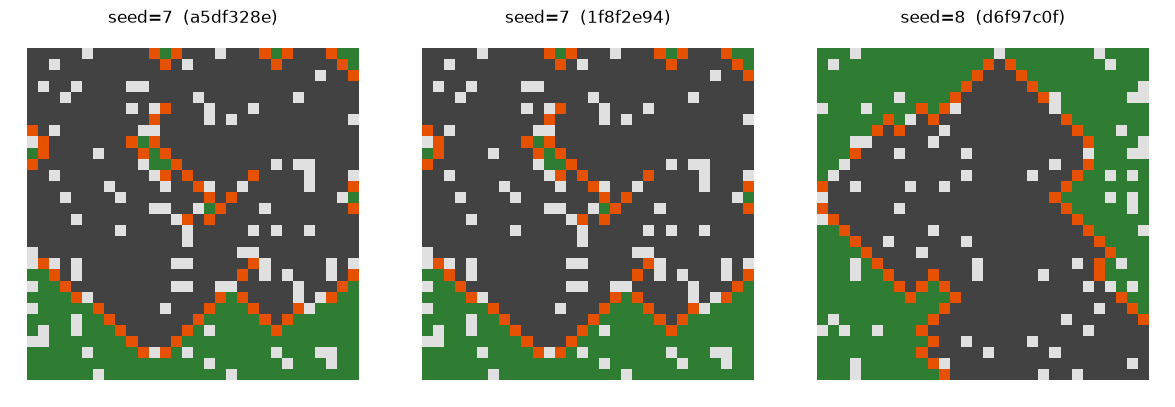

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cores = ListedColormap(["#2e7d32", "#e65100", "#424242", "#e0e0e0"])  # floresta, queimando, queimada, vazia
fig, eixos = plt.subplots(1, len(fixas), figsize=(4 * len(fixas), 4))
for ax, r in zip(eixos, fixas):
    gpd.read_file(r["output_path"]).plot(column="state", cmap=cores, vmin=0, vmax=3, ax=ax)
    ax.set_title(f'seed={r["parameters"]["seed"]}  ({r["experiment_id"][:8]})')
    ax.set_axis_off()
plt.tight_layout()

✏️ **Pergunta 3.** Um modelo com sorteio é reprodutível? Em que condição?

> Um modelo estocástico é reprodutível se a semente for registrada. Para tirar conclusões dele, porém, uma rodada não basta: é preciso várias sementes e olhar a distribuição dos resultados (voltamos a isso no encontro 12).

## 6. O que o registro guarda

Abra o registro de uma execução. Você não escreveu nada disso: o DisSModel preencheu sozinho.

In [17]:
r = fixas[-1]
campos = ["experiment_id", "created_at", "model_name", "model_commit", "code_version",
          "source", "parameters", "output_path", "artifacts", "metrics", "status"]
print(json.dumps({k: r[k] for k in campos}, indent=2, ensure_ascii=False))

{
  "experiment_id": "d6f97c0f9b4d4c788bb3d18f8df9fc91",
  "created_at": "2026-10-31T11:19:15.850417Z",
  "model_name": "fogo",
  "model_commit": "local-cli",
  "code_version": "0.6.6",
  "source": {
    "type": "local",
    "uri": "floresta.gpkg",
    "collection": "",
    "version": "",
    "checksum": "964a8d8431d9e858076aff475411b2b7b424b5f7a64b7fda6b86a271e7a69820"
  },
  "parameters": {
    "initial_fire_density": 0.005,
    "end_time": 8,
    "seed": 8
  },
  "output_path": "saida_fixa/fogo_d6f97c0f.gpkg",
  "artifacts": {
    "output": "f162092b481cf70546280591c32a3776e766cd576ba896ad4993b67be3f04507",
    "profiling": "0b588a58b3f4415b2f608d95b26c6b3ddbd37ebf41e0d727fbdd5d5ce38b2acc"
  },
  "metrics": {
    "celulas_queimadas": 443,
    "time_validate_sec": 0.0,
    "time_load_sec": 0.366,
    "time_run_sec": 2.267,
    "time_save_sec": 0.025,
    "time_total_sec": 2.657
  },
  "status": "completed"
}


| Campo | Pergunta que responde |
|---|---|
| `experiment_id`, `created_at` | Qual execução é esta, e quando rodou? |
| `model_name`, `model_commit`, `code_version` | Qual modelo e qual versão do código? |
| `source` (com `checksum`) | Qual arquivo de entrada, comprovado pelo hash? |
| `parameters` | Com quais parâmetros, incluindo a semente? |
| `artifacts` | Qual o hash de cada arquivo gerado? |
| `metrics` | O que foi medido, e quanto tempo levou cada passo? |

✏️ **Pergunta 4.** O campo `model_commit` diz `local-cli`. Por quê? O que mudaria se o executor viesse de um pacote instalado com versão (por exemplo, `disslucc==0.5.0`)?

## 7. Quando "igual" não é a pergunta certa

Às vezes os valores não são idênticos, e mesmo assim o resultado está certo. O computador arredonda cada conta, e a ordem das contas muda o último dígito:

In [18]:
a = (0.1 + 0.2) + 0.3
b = 0.1 + (0.2 + 0.3)
print(a, b, "iguais?", a == b, " diferença:", abs(a - b))

0.6000000000000001 0.6 iguais? False  diferença: 1.1102230246251565e-16


Por isso há dois tipos de verificação, e o trabalho deve dizer qual usou:

| Pergunta | Verificação |
|---|---|
| É o arquivo arquivado? | hash do arquivo |
| São os mesmos dados, em outra máquina? | hash dos valores |
| É o mesmo resultado, calculado de novo? | tolerância (maior diferença ≤ ε, com ε justificado) |

O próprio TerraME, rodado oito vezes na mesma máquina, gravou o primeiro lab do LuccME com hashes diferentes, todos a menos de 10⁻¹² um do outro.

## 8. Registrar o ambiente

O mesmo código pode dar outro resultado com outras versões das bibliotecas. A forma mais simples de registrar o ambiente é a lista de tudo que está instalado:

In [19]:
!pip freeze > requirements.lock
!grep -i -E "^(dissmodel|geopandas|numpy|pyogrio)" requirements.lock
import platform, sys
print("Python", sys.version.split()[0], "|", platform.platform())

dissmodel==0.6.6
dissmodel-ca @ git+https://github.com/DisSModel/dissmodel-ca.git@23684708ab51e6af53f39e797fc54041de7aaf93
geopandas==1.2.0
numpy==2.5.4
pyogrio==0.13.0


Python 3.13.18 | Linux-6.18.44-fc-v185-x86_64-with-glibc2.39


## 9. Para levar ao projeto

Checklist de reprodutibilidade do projeto da disciplina:

- [ ] Parâmetros num arquivo de configuração, não no código.
- [ ] Semente registrada (e várias sementes, se o modelo for estocástico).
- [ ] Hash dos dados de entrada.
- [ ] Registro de cada execução que vai para o relatório.
- [ ] `requirements.lock` e versão do Python.
- [ ] Um comando, escrito no README, que repete a execução.
- [ ] Verificação declarada: hash do arquivo, hash dos valores ou tolerância.

## Exercícios (entregar até o próximo encontro)

1. Rode o modelo com `initial_fire_density` igual a 0.002, 0.005 e 0.01, com a mesma semente. Faça uma tabela com o identificador, a densidade e as células queimadas, tirada dos registros.
2. Peça a um colega o `floresta.gpkg` e o `model.toml` dele e rode na sua máquina. Os **valores** batem? E os hashes dos arquivos?
3. Em duas ou três frases: que informação da sua dissertação você hoje **não** conseguiria recuperar daqui a um ano?